In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

from movebench.study import Study
from movebench.datasets import grouped_nll

In [3]:
study = Study.load('5a280544-06db-4c85-9713-842547972edd')
train_ds = study.chip_dataset(split='train', 
                              auto_normalize=False # False to look at raw data
                              ) 
print(f"Train dataset: {len(train_ds)} samples")

Train dataset: 1521 samples


In [4]:
sample_idx = 0


x, mask, transform, crs = train_ds[sample_idx]
print(f"Sample shape: {x.shape}")

Sample shape: torch.Size([63, 79, 77])


In [5]:
import matplotlib.pyplot as plt                                                                                                                                 
import numpy as np                                                                                                                                              
from movebench.config import LAYER_ORDER, LAYERS, get_channel_indices                                                                                           
                                                                                                                                                                
# Channel layout (63 total)                                                                                                                                     
channel_indices = get_channel_indices()                                                                                                                         
for layer_name, (start, end) in channel_indices.items():                                                                                                        
    print(f"{layer_name:20s}: channels {start:2d}-{end-1:2d} ({end-start} bands)")                                                                              
                                                                                                                                                                


modis_lst           : channels  0- 1 (2 bands)
modis_vi            : channels  2- 3 (2 bands)
modis_ndsi          : channels  4- 4 (1 bands)
modis_bai           : channels  5- 5 (1 bands)
era5_land           : channels  6-17 (12 bands)
era5                : channels 18-20 (3 bands)
dem                 : channels 21-21 (1 bands)
modis_lc            : channels 22-39 (18 bands)
modis_cvf_tree      : channels 40-40 (1 bands)
modis_cvf_nontree   : channels 41-41 (1 bands)
modis_cvf_nonveg    : channels 42-42 (1 bands)
hii                 : channels 43-43 (1 bands)
bioclim             : channels 44-62 (19 bands)


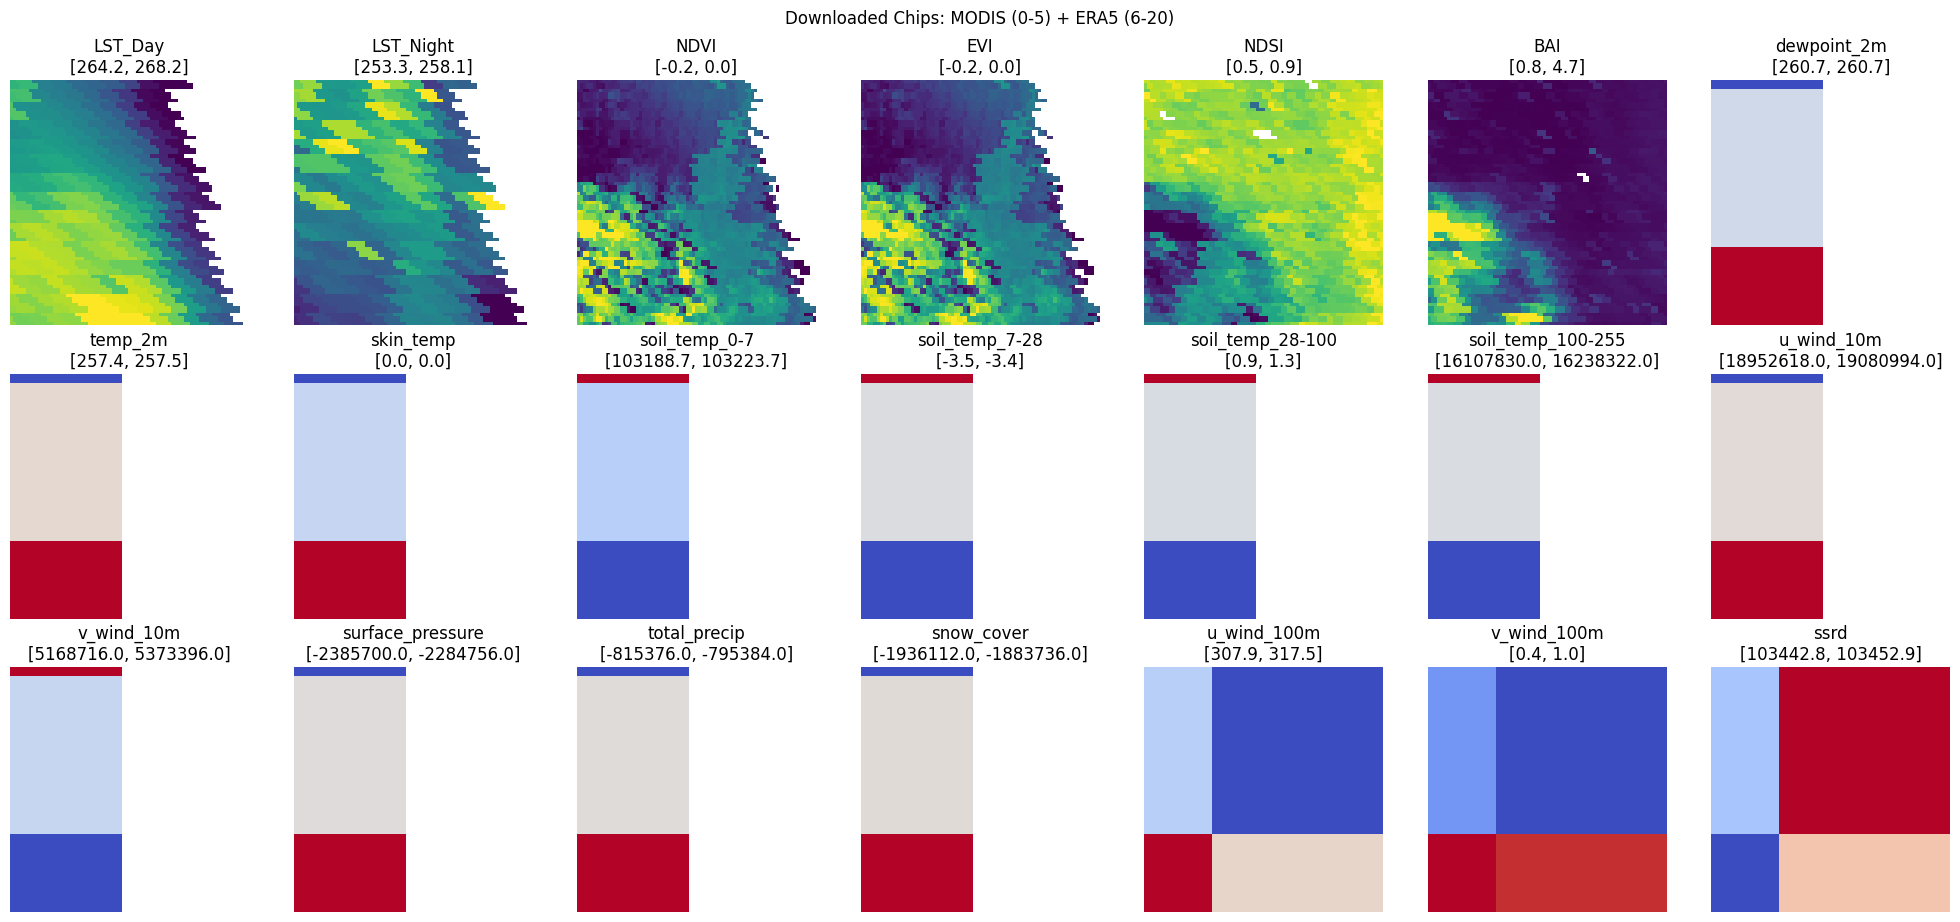

In [6]:
fig, axes = plt.subplots(3, 7, figsize=(20, 9))
axes = axes.flatten()

# MODIS bands (0-5): LST_Day, LST_Night, NDVI, EVI, NDSI, BAI
modis_names = ['LST_Day', 'LST_Night', 'NDVI', 'EVI', 'NDSI', 'BAI']
for i, name in enumerate(modis_names):
    ax = axes[i]
    data = x[i].numpy()
    valid_mask_i = mask[i].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    if len(valid) > 0:
        vmin, vmax = np.percentile(valid, [2, 98])
        im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='viridis')
        ax.set_title(f'{name}\n[{valid.min():.1f}, {valid.max():.1f}]')
    else:
        ax.imshow(display_data)
        ax.set_title(f'{name}\n(no valid data)')
    ax.axis('off')

# ERA5 bands (6-20): 15 atmospheric bands
era5_names = ['dewpoint_2m', 'temp_2m', 'skin_temp', 'soil_temp_0-7',
            'soil_temp_7-28', 'soil_temp_28-100', 'soil_temp_100-255',
            'u_wind_10m', 'v_wind_10m', 'surface_pressure',
            'total_precip', 'snow_cover', 'u_wind_100m', 'v_wind_100m', 'ssrd']
for i, name in enumerate(era5_names):
    ax = axes[6 + i]
    data = x[6 + i].numpy()
    valid_mask_i = mask[6 + i].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    if len(valid) > 0:
        vmin, vmax = np.percentile(valid, [2, 98])
        im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='coolwarm')
        ax.set_title(f'{name}\n[{valid.min():.1f}, {valid.max():.1f}]')
    else:
        ax.imshow(display_data)
        ax.set_title(f'{name}\n(no valid)')
    ax.axis('off')

plt.tight_layout()
plt.suptitle('Downloaded Chips: MODIS (0-5) + ERA5 (6-20)', y=1.02)
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# DEM (channel 21)
ax = axes[0]
dem = x[21].numpy()
valid_mask_dem = mask[21].numpy()
valid = dem[valid_mask_dem]
display_dem = np.where(valid_mask_dem, dem, np.nan)
if len(valid) > 0:
    ax.imshow(display_dem, vmin=np.percentile(valid, 2), vmax=np.percentile(valid, 98), cmap='terrain')
    ax.set_title(f'DEM\n[{valid.min():.0f}m, {valid.max():.0f}m]')
ax.axis('off')

# Land Cover (channels 22-39, one-hot) - show argmax
ax = axes[1]
lc_onehot = x[22:40].numpy()
lc_class = np.argmax(lc_onehot, axis=0)
ax.imshow(lc_class, cmap='tab20')
ax.set_title(f'Land Cover (argmax)\nclasses: {np.unique(lc_class)}')
ax.axis('off')

# CVF bands (40-42)
cvf_names = ['Tree Cover', 'NonTree Veg', 'NonVeg']
for i, name in enumerate(cvf_names):
    ax = axes[2 + i]
    data = x[40 + i].numpy()
    valid_mask_i = mask[40 + i].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    if len(valid) > 0:
        ax.imshow(display_data, vmin=0, vmax=100, cmap='Greens' if i < 2 else 'YlOrBr')
        ax.set_title(f'{name}\n[{valid.min():.0f}%, {valid.max():.0f}%]')
    ax.axis('off')

# HII (channel 43)
ax = axes[5]
hii = x[43].numpy()
valid_mask_hii = mask[43].numpy()
valid = hii[valid_mask_hii]
display_hii = np.where(valid_mask_hii, hii, np.nan)
if len(valid) > 0:
    ax.imshow(display_hii, vmin=np.percentile(valid, 2), vmax=np.percentile(valid, 98), cmap='Reds')
    ax.set_title(f'Human Impact\n[{valid.min():.1f}, {valid.max():.1f}]')
ax.axis('off')

# Hide unused axes
axes[6].axis('off')
axes[7].axis('off')

plt.tight_layout()
plt.suptitle('Other Layers: DEM, LC, CVF, HII', y=1.02)
plt.show()

# BioClim (channels 44-62) - all 19 variables
bioclim_names = [
    'BIO1: Ann Mean Temp',
    'BIO2: Mean Diurnal Range',
    'BIO3: Isothermality',
    'BIO4: Temp Seasonality',
    'BIO5: Max Temp Warmest',
    'BIO6: Min Temp Coldest',
    'BIO7: Temp Ann Range',
    'BIO8: Mean Temp Wettest Q',
    'BIO9: Mean Temp Driest Q',
    'BIO10: Mean Temp Warmest Q',
    'BIO11: Mean Temp Coldest Q',
    'BIO12: Ann Precip',
    'BIO13: Precip Wettest Mo',
    'BIO14: Precip Driest Mo',
    'BIO15: Precip Seasonality',
    'BIO16: Precip Wettest Q',
    'BIO17: Precip Driest Q',
    'BIO18: Precip Warmest Q',
    'BIO19: Precip Coldest Q',
]

fig, axes = plt.subplots(4, 5, figsize=(20, 16))
axes = axes.flatten()

for i, name in enumerate(bioclim_names):
    ax = axes[i]
    ch = 44 + i
    data = x[ch].numpy()
    valid_mask_i = mask[ch].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    
    # Use different colormaps for temperature vs precipitation
    cmap = 'coolwarm' if i < 11 else 'Blues'
    
    if len(valid) > 0:
        vmin, vmax = np.percentile(valid, [2, 98])
        ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(f'{name}\n[{valid.min():.1f}, {valid.max():.1f}]', fontsize=9)
    else:
        ax.imshow(display_data, cmap=cmap)
        ax.set_title(f'{name}\n(no valid data)', fontsize=9)
    ax.axis('off')

# Hide the last unused axis
axes[19].axis('off')

plt.tight_layout()
plt.suptitle('BioClim Variables (19 layers)', y=1.01)
plt.show()